# 02 — Exploratory Data Analysis (EDA)
Analisis statistik deskriptif, distribusi target dan fitur, korelasi Spearman/Pearson, komparasi wilayah, serta bias sampel pada **1.384 data bersih**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

from house_price.config import FITUR_NUM
from house_price.data.cleaning import load_or_build_clean_data
from house_price.visualization.plots import (
    plot_target_distribution,
    plot_feature_distributions,
    plot_area_vs_price_loglog,
    plot_room_carport_boxplots,
    plot_wilayah_boxplot,
    plot_correlation_heatmap,
    plot_sample_bias,
)

df_clean = load_or_build_clean_data()
print(f"Data bersih dimuat: {df_clean.shape[0]:,} baris x {df_clean.shape[1]} kolom")

Data bersih dimuat: 1,384 baris x 13 kolom


## 1. Statistik Deskriptif & Distribusi Target (`harga`)

,count,mean,std,min,5%,25%,50%,75%,95%,max,skewness,missing
harga_juta,"1,384.00","1,584.28","1,643.60",155.00,287.45,645.00,996.50,"1,950.00","4,692.50","16,000.00",3.41,0
luas_tanah,"1,384.00",169.17,201.42,36.00,71.00,97.00,120.00,165.25,435.40,"4,222.00",9.26,0
luas_bangunan,"1,384.00",128.86,110.65,23.00,36.00,60.00,100.00,156.00,339.25,"1,000.00",3.28,0
kamar_tidur,"1,369.00",3.24,1.23,1.00,2.00,2.00,3.00,4.00,5.00,10.00,1.56,15
kamar_mandi,"1,368.00",2.31,1.25,1.00,1.00,1.00,2.00,3.00,5.00,10.00,1.34,16
carport,"1,164.00",1.45,0.97,1.00,1.00,1.00,1.00,2.00,3.00,15.00,5.30,220


Harga <= Rp 1 miliar : 51.3%
Harga <= Rp 2 miliar : 77.7%
Mean/median harga    : 1.59x
Skewness log10(harga): 0.27


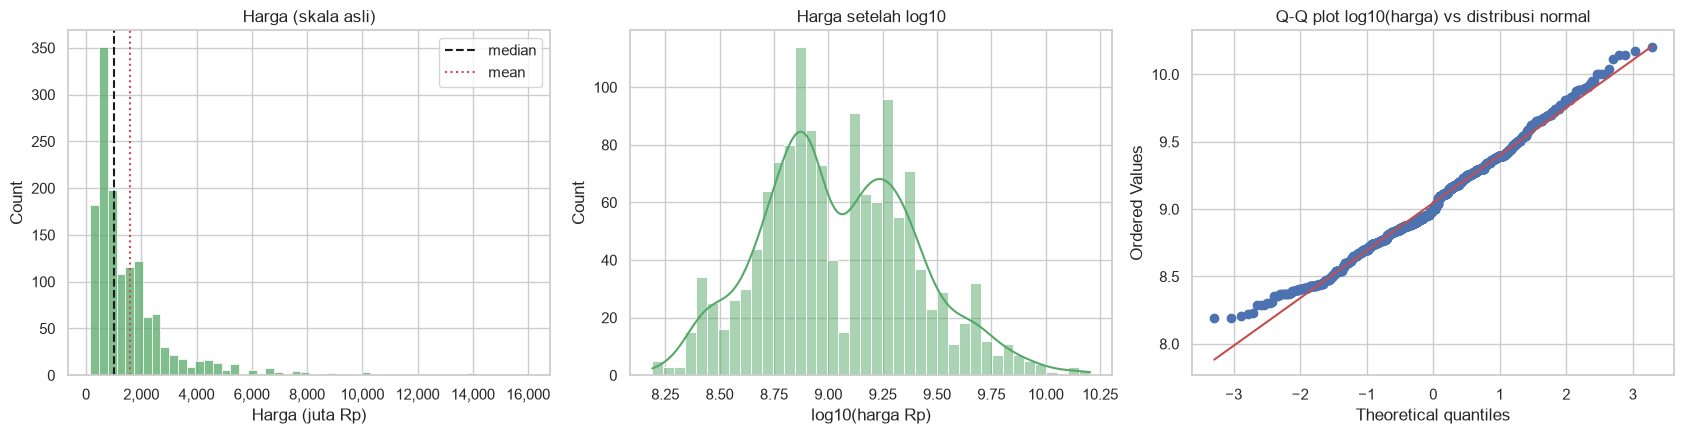

In [2]:
NUM_TAMPIL = ["harga_juta", "luas_tanah", "luas_bangunan", "kamar_tidur", "kamar_mandi", "carport"]
desk = df_clean[NUM_TAMPIL].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
desk["skewness"] = df_clean[NUM_TAMPIL].skew()
desk["missing"] = df_clean[NUM_TAMPIL].isna().sum()
display(desk)

print(f"Harga <= Rp 1 miliar : {(df_clean['harga'] <= 1e9).mean()*100:.1f}%")
print(f"Harga <= Rp 2 miliar : {(df_clean['harga'] <= 2e9).mean()*100:.1f}%")
print(f"Mean/median harga    : {df_clean['harga'].mean()/df_clean['harga'].median():.2f}x")
print(f"Skewness log10(harga): {np.log10(df_clean['harga']).skew():.2f}")

fig = plot_target_distribution(df_clean)
plt.show()

## 2. Distribusi Fitur & Hubungan Bivariat dengan Target

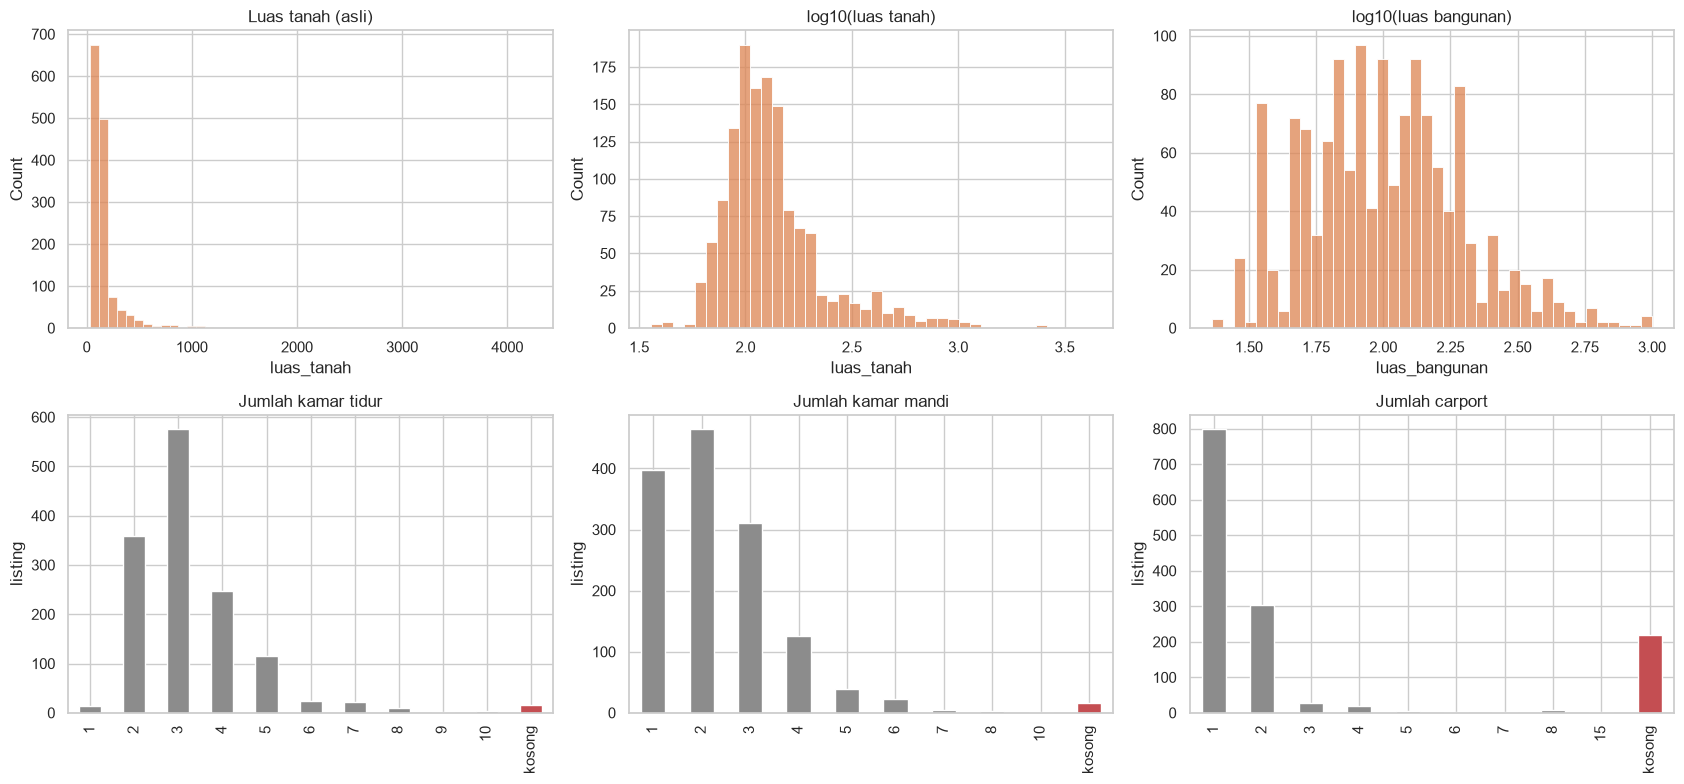

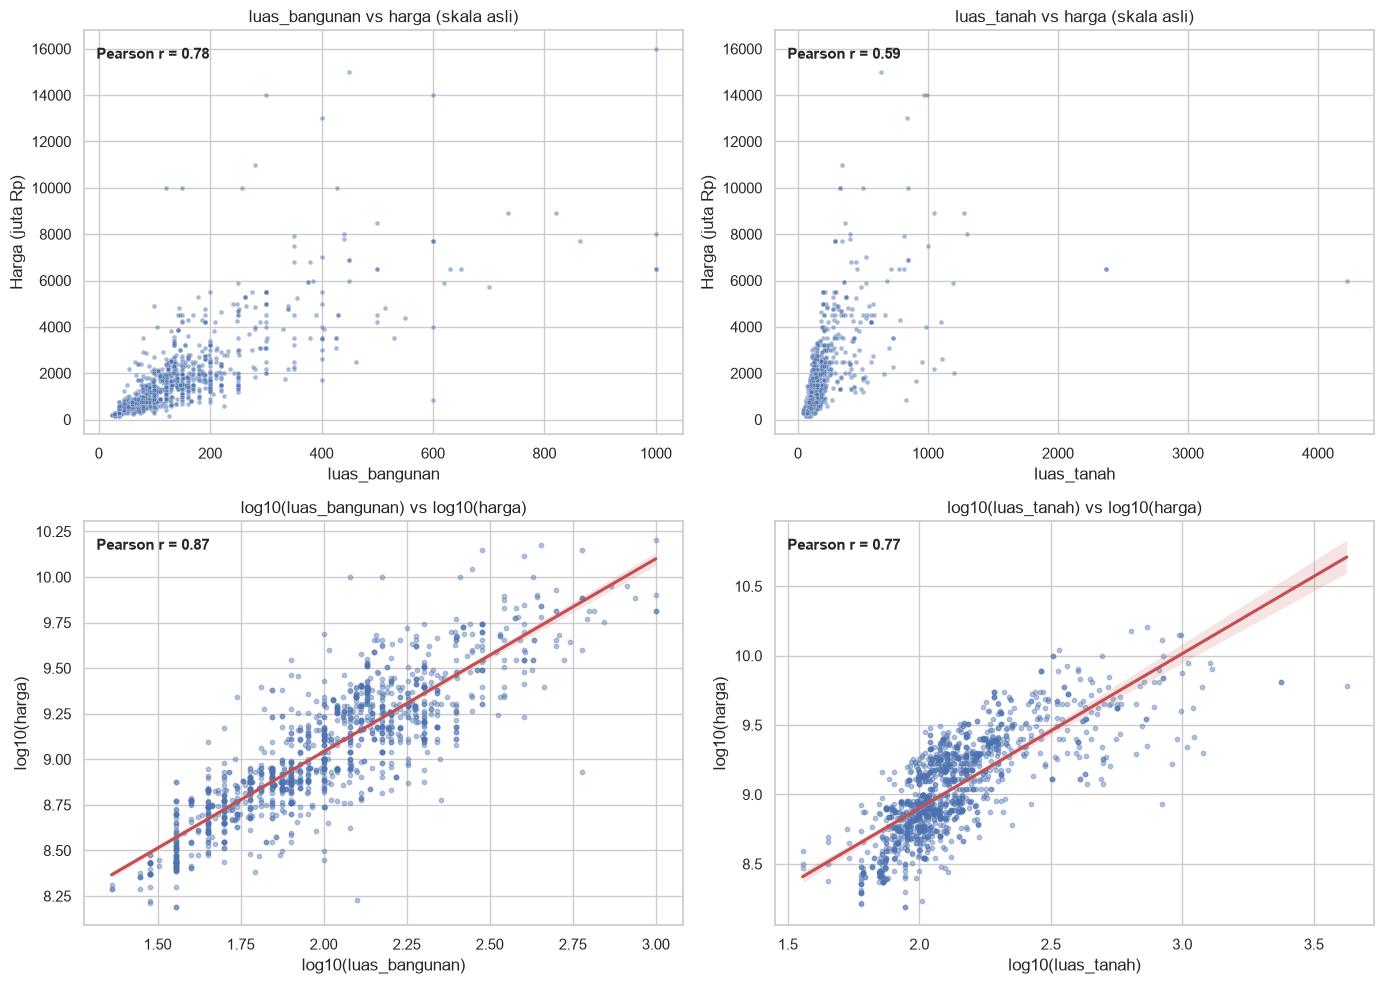

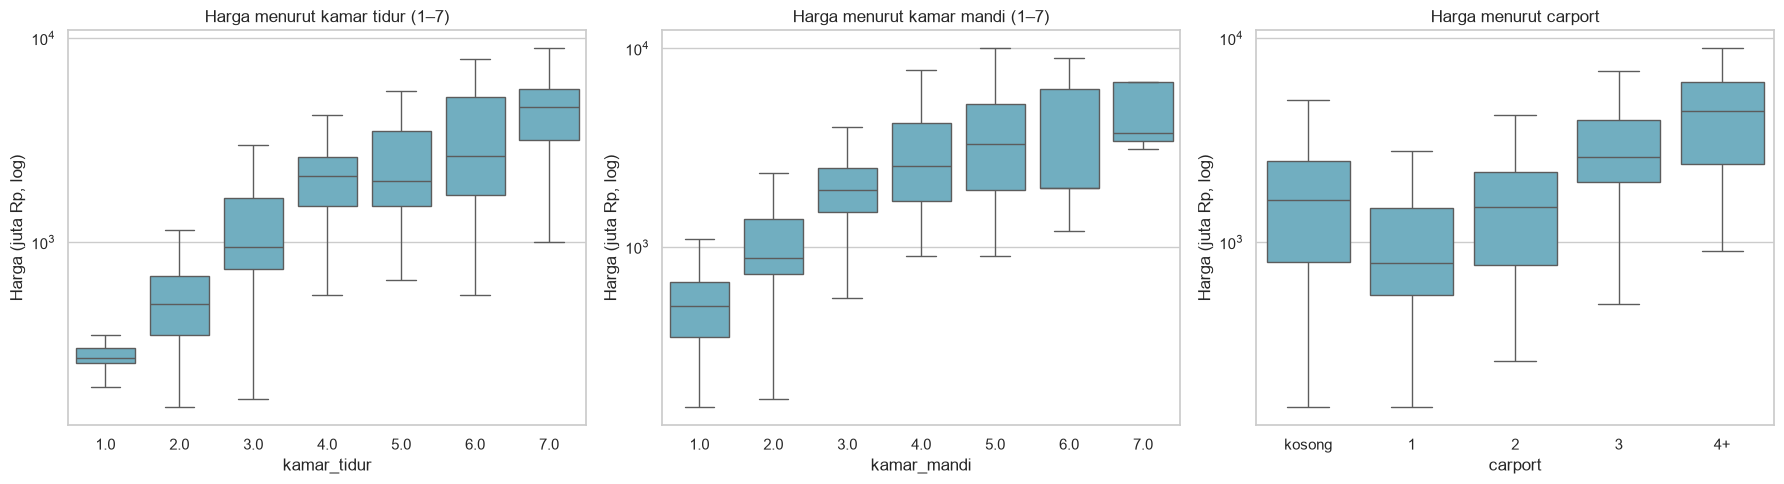

In [3]:
fig = plot_feature_distributions(df_clean)
plt.show()

fig = plot_area_vs_price_loglog(df_clean)
plt.show()

fig = plot_room_carport_boxplots(df_clean)
plt.show()

## 3. Disparitas Wilayah Administratif & Uji Kruskal-Wallis

,listing,median_harga_juta,median_LT,median_LB,porsi_%,median_harga_per_m2_LB_juta
wilayah,,,,,,
Kota Yogyakarta,131,"1,400.00",135.00,129.00,9.47,11.84
Sleman,1003,"1,250.00",125.00,105.00,72.47,10.94
Bantul,217,665.00,97.00,60.00,15.68,10.00
Gunung Kidul,5,310.00,72.00,75.00,0.36,6.75
Kulon Progo,28,278.00,71.00,36.00,2.02,7.72


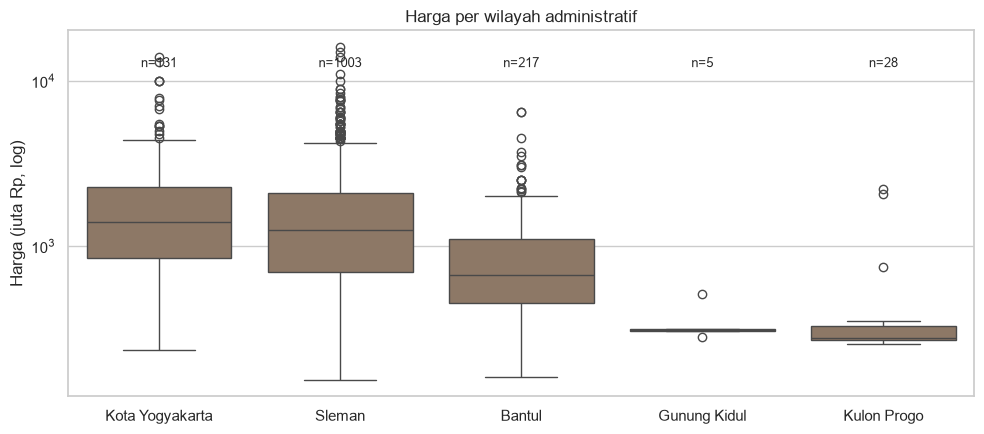

Kruskal-Wallis H = 154.7, p-value = 2.04e-32


In [4]:
wil = (
    df_clean.groupby("wilayah")
    .agg(
        listing=("harga", "size"),
        median_harga_juta=("harga_juta", "median"),
        median_LT=("luas_tanah", "median"),
        median_LB=("luas_bangunan", "median"),
    )
    .sort_values("median_harga_juta", ascending=False)
)
wil["porsi_%"] = wil["listing"] / wil["listing"].sum() * 100
wil["median_harga_per_m2_LB_juta"] = (
    df_clean.assign(h=df_clean["harga"] / df_clean["luas_bangunan"] / 1e6).groupby("wilayah")["h"].median()
)
display(wil)

fig = plot_wilayah_boxplot(df_clean, wil)
plt.show()

h_stat, p_val = stats.kruskal(*[g["harga"].values for _, g in df_clean.groupby("wilayah")])
print(f"Kruskal-Wallis H = {h_stat:.1f}, p-value = {p_val:.2e}")

## 4. Analisis Korelasi, Cek Carport MNAR, & Representativitas Sampel

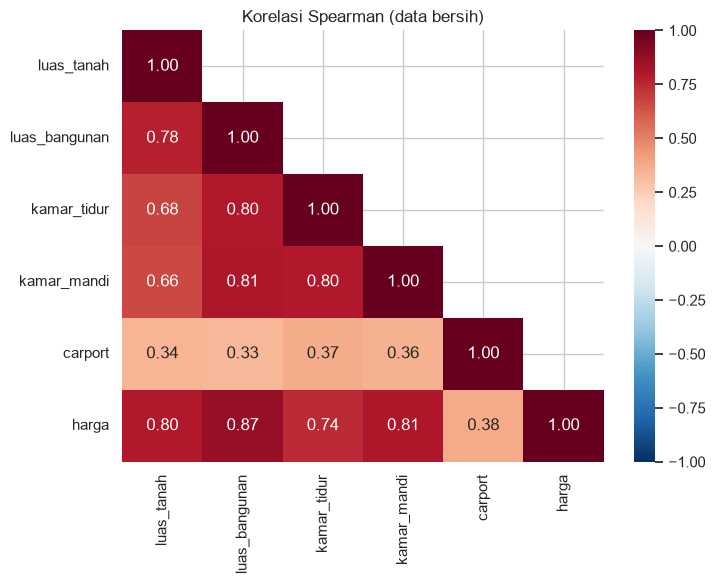

,spearman,pearson_asli,pearson_log_harga,pearson_log_log
luas_bangunan,0.87,0.78,0.74,0.87
kamar_mandi,0.81,0.61,0.73,NaN
luas_tanah,0.80,0.59,0.50,0.77
kamar_tidur,0.74,0.57,0.68,NaN
carport,0.38,0.46,0.41,NaN


,listing,median_harga_juta,median_LB,median_LT,median_KM
carport_kosong,,,,,
0,1164,900.00,91.50,115.00,2.00
1,220,"1,600.00",130.00,144.50,2.00


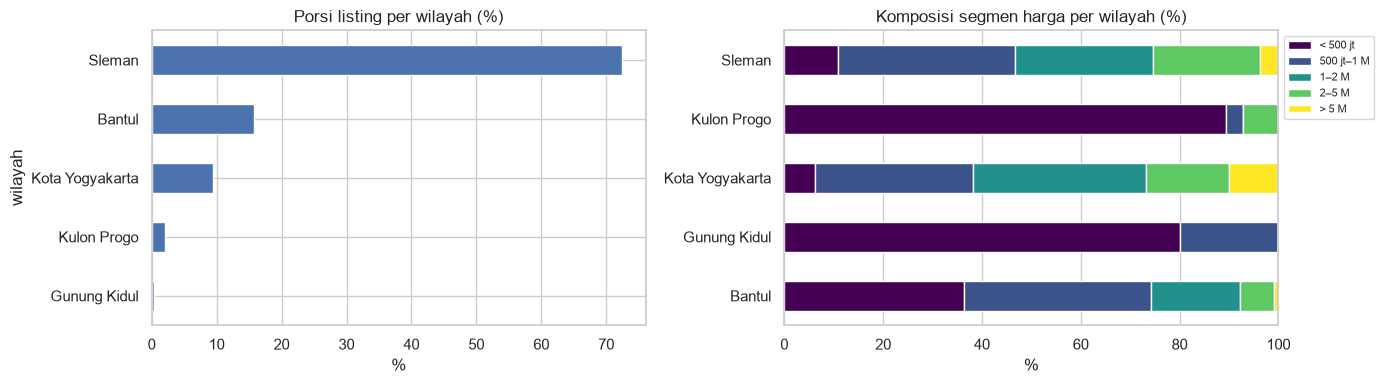

In [5]:
kor = df_clean[FITUR_NUM + ["harga"]].corr(method="spearman")
fig = plot_correlation_heatmap(kor)
plt.show()

log_df_ = df_clean.assign(
    **{f"log_{k}": np.log10(df_clean[k]) for k in ["luas_tanah", "luas_bangunan"]},
    log_harga=np.log10(df_clean["harga"]),
)
kor_target = pd.DataFrame({
    "spearman": kor["harga"].drop("harga"),
    "pearson_asli": df_clean[FITUR_NUM + ["harga"]].corr()["harga"].drop("harga"),
    "pearson_log_harga": log_df_[FITUR_NUM + ["log_harga"]].corr()["log_harga"].drop("log_harga"),
})
kor_target.loc[["luas_tanah", "luas_bangunan"], "pearson_log_log"] = [
    log_df_[["log_luas_tanah", "log_harga"]].corr().iloc[0, 1],
    log_df_[["log_luas_bangunan", "log_harga"]].corr().iloc[0, 1],
]
display(kor_target.sort_values("spearman", ascending=False))

kosong_vs_isi = (
    df_clean.assign(carport_kosong=df_clean["carport"].isna().astype(int))
    .groupby("carport_kosong")
    .agg(
        listing=("harga", "size"),
        median_harga_juta=("harga_juta", "median"),
        median_LB=("luas_bangunan", "median"),
        median_LT=("luas_tanah", "median"),
        median_KM=("kamar_mandi", "median"),
    )
)
display(kosong_vs_isi)

fig = plot_sample_bias(df_clean, wil)
plt.show()

### 5 Insight Utama dari EDA
1. **Ukuran fisik dominan:** `luas_bangunan` ($r_s = 0.87$) dan `luas_tanah` ($r_s = 0.80$) paling kuat berkorelasi dengan harga.
2. **Hubungan multiplikatif (log-log):** transformasi $\log_{10}$ pada harga & luas menstabilkan varians dan menaikkan korelasi Pearson secara tajam.
3. **Potensi multikolinearitas:** `luas_bangunan`, `kamar_mandi`, dan `kamar_tidur` saling berkorelasi $\ge 0.80$ → perlu diuji lewat VIF & *drop-column importance*.
4. **Carport MNAR:** kelompok `carport` kosong bermedian harga lebih tinggi karena ukuran bangunannya lebih besar (harga/m² hampir identik).
5. **Disparitas wilayah:** perbedaan harga antarwilayah signifikan ($p \ll 0.05$); Sleman mendominasi (±72%) sementara Kulon Progo & Gunung Kidul langka → digabung saat modeling.